<a href="https://colab.research.google.com/github/yusza1/data/blob/master/Bab10_Buku_Pemprograman_Web_di_Era_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 10 — Membangun Fitur Cerdas Berbasis AI pada Aplikasi Web
**Studi kasus: Wanderlust AI: Smart Travel Planner**

Notebook pendamping buku *Pemrograman Web di Era AI: Dari Konsep hingga Aplikasi Cerdas*.

Cara memakai:
1. Jalankan sel dari atas ke bawah dengan **Shift + Enter**.
2. Bagian B dan C (sebelum langkah API) **tidak** memerlukan *API key*.
3. Bagian C (langkah 3–4), D, dan E memerlukan *API key* Gemini. Buat gratis di Google AI Studio, lalu simpan di panel **Secrets** Colab (ikon kunci di kiri) dengan nama `GEMINI_API_KEY` dan aktifkan *Notebook access*.
4. Disarankan memakai *runtime* GPU (Runtime → Change runtime type → T4 GPU) agar IndoBERT berjalan lebih cepat, meskipun CPU juga bisa.

## Persiapan: instal *library*

In [ ]:
# transformers, scikit-learn, pandas, dan pydantic umumnya sudah tersedia di Colab.
# google-genai adalah SDK resmi Gemini API.
!pip install -q -U google-genai

---
## B. Analisis Sentimen dan Klasifikasi Aspek Ulasan dengan IndoBERT

**Langkah 1 — Menyiapkan data ulasan.** Untuk latihan, kita memakai beberapa ulasan contoh.

In [ ]:
import pandas as pd

# Ulasan contoh: (nama destinasi, isi ulasan)
data_ulasan = [
    ("Pantai Parangtritis", "Sunset-nya indah banget, tapi toiletnya kotor dan bau."),
    ("Pantai Parangtritis", "Tiket masuk murah, parkir juga luas."),
    ("Candi Prambanan", "Petugasnya ramah, candinya bersih dan terawat."),
    ("Candi Prambanan", "Harga tiket untuk turis asing cukup mahal."),
    ("Gumuk Pasir", "Jalan menuju lokasi rusak, tapi pemandangannya keren."),
]
df = pd.DataFrame(data_ulasan, columns=["destinasi", "ulasan"])
df

**Langkah 2 — Memuat model IndoBERT untuk sentimen.** Fungsi `pipeline` mengunduh model dari Hugging Face sekaligus menyiapkannya.

In [ ]:
from transformers import pipeline

# Unduh model IndoBERT sentimen dari Hugging Face (hanya sekali)
analisis_sentimen = pipeline(
    "sentiment-analysis",
    model="mdhugol/indonesia-bert-sentiment-classification"
)

# Model mengeluarkan label teknis, kita ubah ke bahasa manusia
LABEL = {"LABEL_0": "positif", "LABEL_1": "netral", "LABEL_2": "negatif"}

# Uji coba satu kalimat
prediksi = analisis_sentimen("Pemandangannya luar biasa, wajib datang saat sunset!")[0]
print(LABEL[prediksi["label"]], round(prediksi["score"], 3))

**Langkah 3 — Mengenali aspek dengan IndoBERT.** IndoBERT mengubah setiap klausa menjadi *embedding* (deretan angka yang menangkap makna), lalu pengklasifikasi sederhana belajar dari contoh klausa berlabel aspek. Ulasan dipecah dulu menjadi klausa karena satu ulasan bisa memuat beberapa aspek dan sentimen.

In [ ]:
import re
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression

# IndoBERT (tanpa fine-tuning) untuk mengubah teks menjadi embedding
tokenizer = AutoTokenizer.from_pretrained("indobenchmark/indobert-base-p1")
indobert = AutoModel.from_pretrained("indobenchmark/indobert-base-p1")
indobert.eval()

def embed(daftar_teks):
    masukan = tokenizer(daftar_teks, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        keluaran = indobert(**masukan).last_hidden_state
    mask = masukan["attention_mask"].unsqueeze(-1)
    return ((keluaran * mask).sum(1) / mask.sum(1)).numpy()   # rata-rata per klausa

# Contoh klausa berlabel aspek (4 contoh per aspek)
contoh = {
    "Kebersihan":  ["toiletnya kotor dan bau", "banyak sampah berserakan",
                    "tempatnya bersih dan terawat", "area wisata sangat bersih"],
    "Harga":       ["tiket masuk murah", "harga tiketnya mahal",
                    "tarif masuk sangat terjangkau", "harga makanan terlalu mahal"],
    "Fasilitas":   ["parkirnya luas", "mushola tersedia dan nyaman",
                    "ada gazebo dan wifi gratis", "fasilitas lengkap untuk keluarga"],
    "Akses":       ["jalan menuju lokasi rusak", "akses jalan sempit dan macet",
                    "lokasinya jauh dari pusat kota", "jalannya mulus dan mudah dijangkau"],
    "Pelayanan":   ["petugasnya ramah", "pemandu sangat membantu",
                    "staf tidak responsif", "pelayanan cepat dan sopan"],
    "Pemandangan": ["sunset-nya indah banget", "pemandangannya keren",
                    "udara sejuk dan view bagus", "panorama alamnya memukau"],
}
teks_latih = [k for daftar in contoh.values() for k in daftar]
label_latih = [a for a, daftar in contoh.items() for _ in daftar]

# Pengklasifikasi sederhana di atas embedding IndoBERT
pengklasifikasi = LogisticRegression(max_iter=1000)
pengklasifikasi.fit(embed(teks_latih), label_latih)

def pecah_klausa(teks):
    # Pisahkan kalimat pada tanda baca dan kata "tapi"/"namun"
    bagian = re.split(r"[.,!?;]|\btapi\b|\bnamun\b", teks.lower())
    return [b.strip() for b in bagian if b.strip()]

def deteksi_aspek(klausa, ambang=0.3):
    # Kembalikan aspek dengan peluang tertinggi, atau None jika kurang yakin
    peluang = pengklasifikasi.predict_proba(embed([klausa]))[0]
    if peluang.max() < ambang:
        return None
    return pengklasifikasi.classes_[peluang.argmax()]

# Uji coba
for k in pecah_klausa("Sunset-nya indah banget, tapi toiletnya kotor dan bau."):
    print(k, "->", deteksi_aspek(k))

**Langkah 4 — Menggabungkan sentimen dan aspek.** Hasil sel ini dipakai untuk **Gambar 10.2**.

In [ ]:
hasil = []
for _, baris in df.iterrows():
    for klausa in pecah_klausa(baris["ulasan"]):
        aspek = deteksi_aspek(klausa)              # tanya IndoBERT: aspek apa?
        if aspek is None:                          # lewati klausa tanpa aspek
            continue
        prediksi = analisis_sentimen(klausa)[0]    # tanya IndoBERT: sentimennya?
        hasil.append({
            "destinasi": baris["destinasi"],
            "klausa": klausa,
            "aspek": aspek,
            "sentimen": LABEL[prediksi["label"]],
        })

df_aspek = pd.DataFrame(hasil)

# Rekap: jumlah sentimen per destinasi dan per aspek
rekap = (df_aspek.groupby(["destinasi", "aspek"])["sentimen"]
         .value_counts().unstack(fill_value=0))
rekap

*(Opsional)* Tampilkan rekap sebagai grafik batang, seperti "kartu rapor" destinasi.

In [ ]:
import matplotlib.pyplot as plt

warna = {"positif": "#2e7d32", "netral": "#9e9e9e", "negatif": "#c62828"}
kolom = [k for k in ["positif", "netral", "negatif"] if k in rekap.columns]
ax = rekap[kolom].plot(kind="barh", stacked=True, figsize=(7, 4),
                       color=[warna[k] for k in kolom])
ax.set_xlabel("Jumlah klausa")
ax.set_ylabel("")
ax.set_title("Rekap sentimen per aspek")
plt.tight_layout()
plt.show()

---
## C. Sistem Rekomendasi Destinasi (*Content-Based Filtering*)

**Langkah 1 — Menyiapkan data destinasi dan pengguna.** Data destinasi dan harga tiket adalah data ilustrasi untuk latihan.

In [ ]:
import pandas as pd

# Data destinasi ilustrasi: nama, kata kunci deskripsi, harga tiket (Rp)
destinasi = pd.DataFrame([
    ("Candi Prambanan",     "budaya sejarah candi hindu arsitektur foto",     50000),
    ("Candi Borobudur",     "budaya sejarah candi buddha sunrise arsitektur", 50000),
    ("Keraton Yogyakarta",  "budaya sejarah istana tradisi jawa museum",      15000),
    ("Taman Sari",          "budaya sejarah istana air foto arsitektur",      15000),
    ("Malioboro",           "kuliner belanja jalan kaki budaya malam",            0),
    ("Pantai Parangtritis", "alam pantai sunset ombak keluarga",              10000),
    ("Gumuk Pasir",         "alam petualangan sandboarding gurun pasir",      10000),
    ("HeHa Sky View",       "kuliner kafe pemandangan kota foto malam",       20000),
    ("Kalibiru",            "alam pegunungan hutan foto ketinggian",          10000),
    ("Gudeg Yu Djum",       "kuliner makanan khas jawa gudeg sarapan",            0),
], columns=["nama", "deskripsi", "tiket"])

# Profil, preferensi, dan riwayat Rina
pengguna = {
    "nama": "Rina",
    "preferensi": "budaya sejarah kuliner",
    "anggaran_tiket": 30000,
    "favorit": ["Candi Prambanan"],
}
destinasi

,nama,deskripsi,tiket
0,Candi Prambanan,budaya sejarah candi hindu arsitektur foto,50000
1,Candi Borobudur,budaya sejarah candi buddha sunrise arsitektur,50000
2,Keraton Yogyakarta,budaya sejarah istana tradisi jawa museum,15000
3,Taman Sari,budaya sejarah istana air foto arsitektur,15000
4,Malioboro,kuliner belanja jalan kaki budaya malam,0
5,Pantai Parangtritis,alam pantai sunset ombak keluarga,10000
6,Gumuk Pasir,alam petualangan sandboarding gurun pasir,10000
7,HeHa Sky View,kuliner kafe pemandangan kota foto malam,20000
8,Kalibiru,alam pegunungan hutan foto ketinggian,10000
9,Gudeg Yu Djum,kuliner makanan khas jawa gudeg sarapan,0


**Langkah 2 — Menghitung kemiripan (TF-IDF + *cosine similarity*).** Hasil sel ini dipakai untuk **Gambar 10.3**.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Gabungkan preferensi + deskripsi destinasi favorit menjadi profil teks
favorit = destinasi[destinasi["nama"].isin(pengguna["favorit"])]
profil_teks = pengguna["preferensi"] + " " + " ".join(favorit["deskripsi"])

# Ubah teks menjadi angka (TF-IDF), lalu ukur kemiripannya
vectorizer = TfidfVectorizer()
matriks = vectorizer.fit_transform(destinasi["deskripsi"])
vektor_profil = vectorizer.transform([profil_teks])
destinasi["skor"] = cosine_similarity(vektor_profil, matriks).flatten().round(2)

# Saring: belum pernah difavoritkan dan sesuai anggaran tiket
kandidat = destinasi[
    (~destinasi["nama"].isin(pengguna["favorit"])) &
    (destinasi["tiket"] <= pengguna["anggaran_tiket"])
]
top5 = kandidat.sort_values("skor", ascending=False).head(5).reset_index(drop=True)
top5.index = top5.index + 1          # peringkat mulai dari 1
top5[["nama", "skor", "tiket"]]

,nama,skor,tiket
1,Taman Sari,0.54,15000
2,Keraton Yogyakarta,0.30,15000
3,Malioboro,0.23,0
4,HeHa Sky View,0.18,20000
5,Gudeg Yu Djum,0.10,0


**Langkah 3 — Menyiapkan Gemini API.** *API key* diambil dari panel Secrets, tidak ditulis di dalam kode.

In [ ]:
from google import genai
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

# Nama model dapat berubah; cek daftar model terbaru di dokumentasi Gemini API
MODEL_TEKS = "gemini-3.1-flash-lite"

**Langkah 4 — Meminta AI menjelaskan rekomendasi.** AI hanya menjelaskan daftar yang sudah dipilih sistem, tidak mencari destinasi sendiri. Hasil sel ini dipakai untuk **Gambar 10.4**.

In [ ]:
daftar = "\n".join(f"- {n}: {d}" for n, d in zip(top5["nama"], top5["deskripsi"]))

prompt = f"""
Kamu adalah pemandu wisata yang ramah.
Pengguna bernama {pengguna['nama']} menyukai: {pengguna['preferensi']}.
Berikut destinasi yang sudah dipilih sistem untuknya:
{daftar}

Tulis satu kalimat alasan untuk setiap destinasi, dalam bahasa Indonesia santai.
Jangan menambahkan destinasi lain di luar daftar.
"""

respons = client.models.generate_content(model=MODEL_TEKS, contents=prompt)
print(respons.text)

Halo Rina! Senang sekali bisa membantu kamu merencanakan perjalanan. Ini alasan kenapa destinasi-destinasi ini cocok banget buat kamu:

*   **Taman Sari:** Kamu pasti bakal jatuh cinta sama arsitektur istana air yang estetik dan kental dengan nilai sejarahnya buat bahan foto-foto keren.
*   **Keraton Yogyakarta:** Tempat yang wajib banget kamu kunjungi kalau mau belajar tradisi Jawa yang masih terjaga keasliannya di setiap sudut museumnya.
*   **Malioboro:** Kurang lengkap rasanya ke Jogja kalau belum jalan kaki santai sambil kulineran dan merasakan langsung denyut budaya lokal di malam hari.
*   **HeHa Sky View:** Cocok banget buat kamu yang pengen santai di kafe sambil menikmati pemandangan kota dari ketinggian dengan suasana malam yang syahdu.
*   **Gudeg Yu Djum:** Ini dia "wajib" buat kamu, sarapan gudeg otentik yang jadi ikon kuliner legendaris paling pas untuk memulai petualanganmu di Jogja.


---
## D. *Generate Itinerary* Otomatis
Bagian ini memakai variabel `top5`, `client`, dan `MODEL_TEKS` dari Bagian C.

**Langkah 1 — Mendefinisikan struktur *itinerary* dengan Pydantic.** Struktur ini menjadi "cetakan" keluaran AI.

In [ ]:
from pydantic import BaseModel

class Kegiatan(BaseModel):
    jam: str          # contoh: "08.00"
    aktivitas: str
    lokasi: str
    biaya: int        # dalam rupiah
    tips: str

class Hari(BaseModel):
    hari_ke: int
    kegiatan: list[Kegiatan]

class Itinerary(BaseModel):
    judul: str
    hari: list[Hari]

**Langkah 2 — Menyusun *prompt* (data, aturan, format) dan memanggil API dengan *structured output*.**

In [ ]:
import json

perjalanan = {
    "kota": "Yogyakarta",
    "durasi_hari": 3,
    "anggaran": 1500000,          # total anggaran kegiatan (Rp)
    "gaya": "santai, banyak waktu untuk foto dan kuliner",
}
daftar_destinasi = ", ".join(top5["nama"])

prompt = f"""
Susun itinerary {perjalanan['durasi_hari']} hari di {perjalanan['kota']}.
Gaya perjalanan: {perjalanan['gaya']}.

ATURAN:
- Gunakan HANYA destinasi berikut: {daftar_destinasi}.
- Total biaya seluruh kegiatan tidak boleh melebihi Rp{perjalanan['anggaran']}.
- Mulai pukul 08.00 dan selesai sebelum 21.00 setiap hari.
- Sisipkan waktu makan siang dan makan malam.
"""

KONFIG_JSON = {
    "response_mime_type": "application/json",               # minta keluaran JSON
    "response_json_schema": Itinerary.model_json_schema(),  # ikuti cetakan
}

respons = client.models.generate_content(model=MODEL_TEKS, contents=prompt, config=KONFIG_JSON)
itinerary = json.loads(respons.text)     # ubah teks JSON menjadi dictionary
print(json.dumps(itinerary, indent=2, ensure_ascii=False)[:1500])

{
  "judul": "Eksplorasi Santai Yogyakarta",
  "hari": [
    {
      "hari_ke": 1,
      "kegiatan": [
        {
          "jam": "08.00-11.00",
          "aktivitas": "Jelajah sejarah dan foto estetik di Taman Sari",
          "lokasi": "Taman Sari",
          "biaya": 15000,
          "tips": "Datang lebih pagi untuk menghindari keramaian saat berfoto"
        },
        {
          "jam": "12.00-13.30",
          "aktivitas": "Makan siang kuliner legendaris",
          "lokasi": "Gudeg Yu Djum",
          "biaya": 75000,
          "tips": "Pilih menu paket agar lebih hemat dan lengkap"
        },
        {
          "jam": "14.00-16.30",
          "aktivitas": "Jalan santai dan foto-foto di area Keraton",
          "lokasi": "Keraton Yogyakarta",
          "biaya": 15000,
          "tips": "Gunakan pakaian yang sopan"
        },
        {
          "jam": "18.00-20.00",
          "aktivitas": "Makan malam dan suasana santai di pusat kota",
          "lokasi": "Malioboro",
          

**Langkah 3 — Menampilkan *itinerary* sebagai tabel.** Hasil sel ini dipakai untuk **Gambar 10.5**.

In [ ]:
def ke_tabel(itinerary):
    # Ratakan struktur hari -> kegiatan menjadi baris-baris tabel
    baris = [{"hari": h["hari_ke"], **k} for h in itinerary["hari"] for k in h["kegiatan"]]
    return pd.DataFrame(baris)

tabel = ke_tabel(itinerary)
print(itinerary["judul"])
tabel[["hari", "jam", "aktivitas", "lokasi", "biaya"]]

Eksplorasi Santai Yogyakarta


,hari,jam,aktivitas,lokasi,biaya
0,1,08.00-11.00,Jelajah sejarah dan foto estetik di Taman Sari,Taman Sari,15000
1,1,12.00-13.30,Makan siang kuliner legendaris,Gudeg Yu Djum,75000
2,1,14.00-16.30,Jalan santai dan foto-foto di area Keraton,Keraton Yogyakarta,15000
3,1,18.00-20.00,Makan malam dan suasana santai di pusat kota,Malioboro,100000
4,2,09.00-11.00,Hunting foto di sekitar kompleks Keraton,Keraton Yogyakarta,15000
5,2,12.00-13.30,Makan siang Gudeg,Gudeg Yu Djum,75000
6,2,16.00-20.00,Menikmati pemandangan senja dan foto di perbuk...,HeHa Sky View,100000
7,3,09.00-12.00,Menikmati nuansa air dan foto bangunan lama,Taman Sari,15000
8,3,12.30-14.00,Makan siang khas,Gudeg Yu Djum,75000
9,3,15.00-20.00,Belanja oleh-oleh dan makan malam santai,Malioboro,200000


**Langkah 4 — Memeriksa keluaran AI dengan kode biasa.** Jika ada masalah, AI diminta memperbaiki (maksimal 3 kali).

In [ ]:
def cek_itinerary(tabel, anggaran):
    masalah = []
    total = tabel["biaya"].sum()
    if total > anggaran:
        masalah.append(f"Total biaya Rp{total} melebihi anggaran Rp{anggaran}")
    if tabel.duplicated(subset=["hari", "jam"]).any():
        masalah.append("Ada dua kegiatan pada jam yang sama di hari yang sama")
    return masalah

for percobaan in range(3):
    masalah = cek_itinerary(tabel, perjalanan["anggaran"])
    if not masalah:
        print("Itinerary lolos pengecekan. Total biaya: Rp", tabel["biaya"].sum())
        break
    print("Perlu perbaikan:", masalah)
    prompt += "\nPerbaiki masalah berikut: " + "; ".join(masalah)
    respons = client.models.generate_content(model=MODEL_TEKS, contents=prompt, config=KONFIG_JSON)
    itinerary = json.loads(respons.text)
    tabel = ke_tabel(itinerary)

---
## E. *AI Image Generation* untuk Konten Perjalanan
Bagian ini memakai objek `client` dari Bagian C.

**Contoh 1 — Membuat sampul *itinerary* (*text-to-image*).** Hasil sel ini dipakai untuk **Gambar 10.6**.

Tentu, ini dia ilustrasinya: 


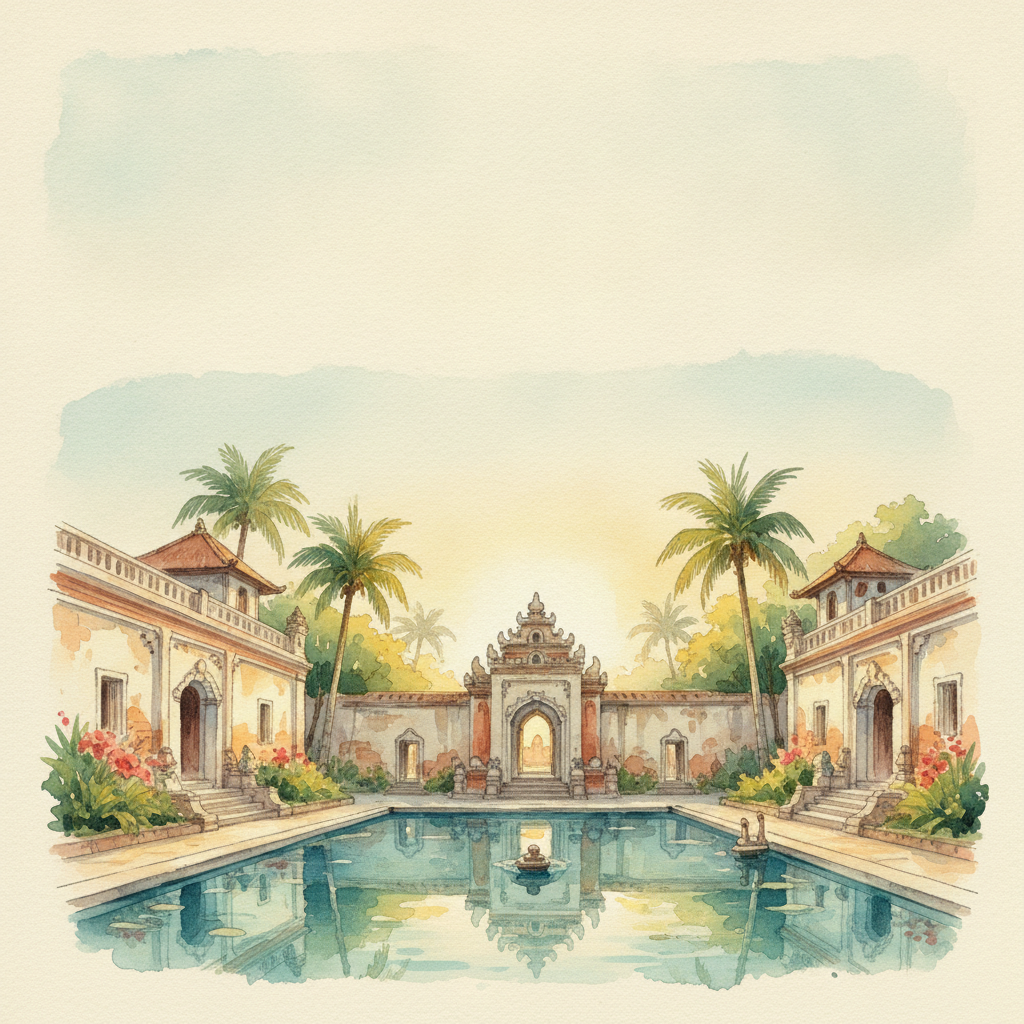

In [ ]:
from PIL import Image

# Nama model dapat berubah; cek daftar model terbaru di dokumentasi Gemini API
MODEL_GAMBAR = "gemini-2.5-flash-image"

prompt_gambar = (
    "Ilustrasi cat air bergaya poster (layout landscape/mendatar) perjalanan vintage: Taman Sari Yogyakarta "
    "saat pagi, kolam berwarna toska, cahaya hangat, rasio 16:9, "
    "dengan ruang kosong di bagian atas untuk judul."
)

respons = client.models.generate_content(model=MODEL_GAMBAR, contents=[prompt_gambar])

# Respons bisa berisi teks dan gambar; simpan bagian yang berupa gambar
for bagian in respons.parts:
    if bagian.inline_data is not None:
        bagian.as_image().save("sampul_itinerary.png")
    elif bagian.text:
        print(bagian.text)

Image.open("sampul_itinerary.png")

**Contoh 2 — Mengubah foto liburan menjadi ilustrasi (*image editing*).** Unggah foto Anda sendiri. Hasil sel ini dipakai untuk **Gambar 10.7** (foto asli dan hasil berdampingan).

Saving istockphoto-530744884-612x612 (1).jpg to istockphoto-530744884-612x612 (1).jpg


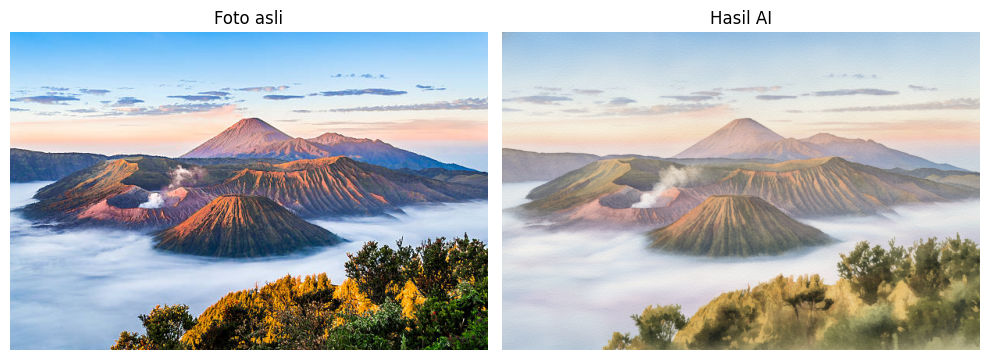

In [22]:
from google.colab import files

unggahan = files.upload()                  # pilih foto dari komputer Anda
nama_file = list(unggahan.keys())[0]
foto = Image.open(nama_file)

instruksi = ("Ubah foto ini menjadi ilustrasi cat air yang lembut. "
             "Pertahankan wajah dan pose orang di foto.")

respons = client.models.generate_content(model=MODEL_GAMBAR, contents=[foto, instruksi])

for bagian in respons.parts:
    if bagian.inline_data is not None:
        bagian.as_image().save("foto_cat_air.png")

# Tampilkan foto asli dan hasil berdampingan
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, gambar, judul in zip(ax, [foto, Image.open("foto_cat_air.png")], ["Foto asli", "Hasil AI"]):
    a.imshow(gambar); a.set_title(judul); a.axis("off")
plt.tight_layout(); plt.show()

---
### Coba Sendiri
1. Tambahkan aspek baru **Keramaian** pada `contoh` di Bagian B, misalnya "tempatnya ramai sekali", "antre tiketnya lama", "suasananya sepi", "pengunjung membludak".
2. Ubah `pengguna["preferensi"]` menjadi `"alam petualangan"` di Bagian C, lalu amati perubahan rekomendasi.
3. Ubah `perjalanan["anggaran"]` menjadi setengahnya di Bagian D, lalu bandingkan *itinerary*-nya.